# IADS5 · TP integrador — Ortelana Textil
### Actividad 05 · Árboles de decisión · Parcial 1

**Integrantes del grupo:** Camila Belén Capua, Franco Salama, Juan Pablo Ruax Debruijn, Lorena Wajchman, Tomas Rossi y Miguel Ángel Tadakuma  
**Comisión:** [Completar]  
**Repositorio GitHub:** https://github.com/francosalama/paa-integrador-ortelana  
**Fecha:** 17/11/2026

> Notebook independiente. Requiere el archivo `particion_train_test.csv` (partición train/test generada por `actividad_01.ipynb`).

## Actividad 05 · Árboles de decisión · Parcial 1

**Qué se espera:** Compará árboles clasificadores con criterion=gini y entropy (max_depth=4 como inicio); explorá también un árbol regresor con profundidades distintas. Visualizá un árbol hasta profundidad 3 y compará importancias y métricas de las actividades 1–5.

**Evidencia a entregar:** Árboles, importancias, tabla acumulada; notebooks 01–05 ejecutables; tag `parcial-1`.

### TODO — Implementación libre
Desarrollá una solución propia. Organizá tantas celdas como necesites; incluí tablas y gráficos con títulos, ejes y unidades cuando correspondan. No alcanza con que el código ejecute: debe permitir comprobar las consignas.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)   # avisos de versión de librerías
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

df = pd.read_csv("ventas_historicas_ortelana_argentina.csv")
# Target de regresión: volumen anual = suma de los metros con dato de cada fila (comparable entre formatos)
df["volumen_anual_metros"] = df[[f"Metros{i}" for i in range(1, 13)]].sum(axis=1, min_count=1)

# Partición de la actividad 01: misma semilla, mismas filas de train y test
target = "Format_Reporte"
features = ["Sucursal_ID", "Tela_ID", "Año", "Metros1", "Metros2"]
train, test = train_test_split(df, test_size=0.2, stratify=df[target], random_state=RANDOM_STATE)

# Control: tiene que coincidir con la partición guardada en particion_train_test.csv
particion = pd.read_csv("particion_train_test.csv", index_col="fila")["particion"]
assert (particion[test.index] == "test").all() and (particion == "test").sum() == len(test)

X_train, X_test = train[features], test[features]
y_train, y_test = train[target], test[target]

# Regresión de volumen_anual_metros (suma anual de los metros con dato): mismas filas de train y test
features_reg = ["Sucursal_ID", "Tela_ID", "Año"]
Xr_train, Xr_test = train[features_reg], test[features_reg]
yr_train, yr_test = train["volumen_anual_metros"], test["volumen_anual_metros"]

print("Train:", X_train.shape, "| Test:", X_test.shape)


Train: (2628, 5) | Test: (657, 5)


In [2]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.metrics import accuracy_score, f1_score

cat_cols = ["Sucursal_ID", "Tela_ID"]          # identificadores: van con one-hot
num_cols = ["Año", "Metros1", "Metros2"]

def crear_pipeline(modelo, numericas=num_cols):
    """One-hot para los identificadores y numéricas sin cambios (los árboles no necesitan escalado)."""
    preprocesador = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
        ("num", "passthrough", numericas),
    ], verbose_feature_names_out=False)   # nombres de columnas cortos, p. ej. "Tela_ID_TELA-001"
    return Pipeline([("prep", preprocesador), ("modelo", modelo)])

In [3]:
# 5.1 Árboles clasificadores: gini vs. entropy con max_depth=4
arbol_gini = crear_pipeline(DecisionTreeClassifier(criterion="gini", max_depth=4, random_state=RANDOM_STATE))
arbol_entropy = crear_pipeline(DecisionTreeClassifier(criterion="entropy", max_depth=4, random_state=RANDOM_STATE))
arbol_gini.fit(X_train, y_train)
arbol_entropy.fit(X_train, y_train)

pred_gini = arbol_gini.predict(X_test)
pred_entropy = arbol_entropy.predict(X_test)

pd.DataFrame({
    "F1 macro train": [f1_score(y_train, arbol_gini.predict(X_train), average="macro"),
                       f1_score(y_train, arbol_entropy.predict(X_train), average="macro")],
    "Accuracy test": [accuracy_score(y_test, pred_gini), accuracy_score(y_test, pred_entropy)],
    "F1 macro test": [f1_score(y_test, pred_gini, average="macro"), f1_score(y_test, pred_entropy, average="macro")],
}, index=["Árbol gini", "Árbol entropy"]).round(4)

,F1 macro train,Accuracy test,F1 macro test
Árbol gini,0.6389,0.6545,0.6460
Árbol entropy,0.6037,0.6256,0.6101


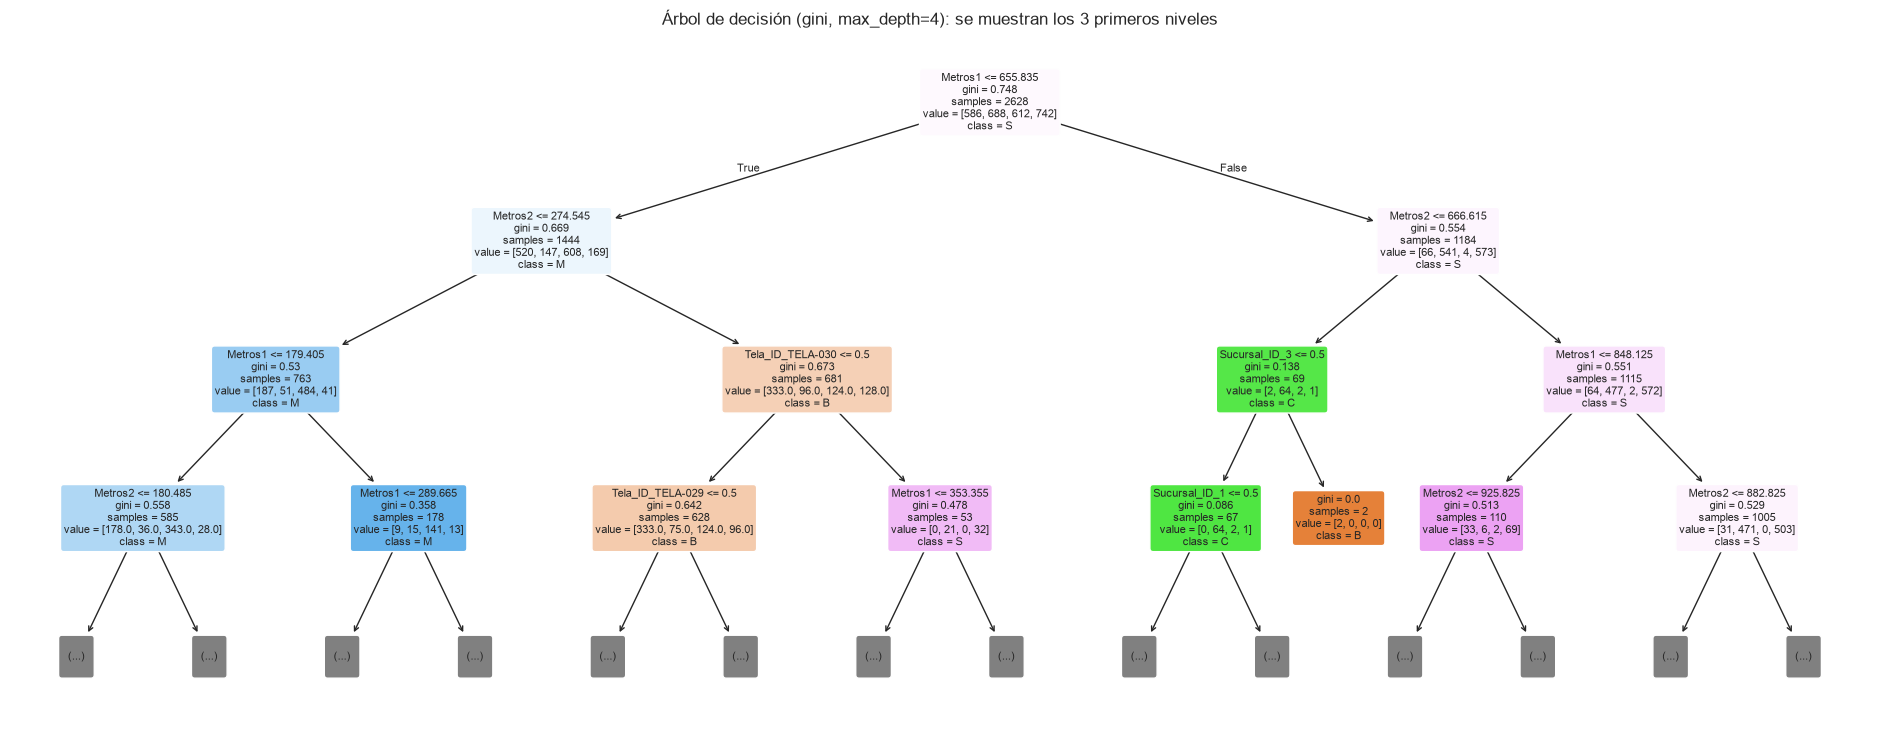

gini: primera partición -> Metros1 <= 655.84
entropy: primera partición -> Metros1 <= 691.00


In [4]:
# 5.2 Visualización del árbol (gini) hasta profundidad 3
nombres = arbol_gini.named_steps["prep"].get_feature_names_out()

plt.figure(figsize=(24, 9))
plot_tree(arbol_gini.named_steps["modelo"], feature_names=nombres, class_names=arbol_gini.classes_,
          max_depth=3, filled=True, rounded=True, fontsize=8)
plt.title("Árbol de decisión (gini, max_depth=4): se muestran los 3 primeros niveles")
plt.show()

# Primera partición (nodo raíz) de cada árbol
for nombre, arbol in [("gini", arbol_gini), ("entropy", arbol_entropy)]:
    raiz = arbol.named_steps["modelo"].tree_
    print(f"{nombre}: primera partición -> {nombres[raiz.feature[0]]} <= {raiz.threshold[0]:.2f}")

,gini,entropy
Metros1,0.5486,0.6783
Metros2,0.3695,0.2811
Tela_ID,0.0719,0.0318
Sucursal_ID,0.0100,0.0088
Año,0.0000,0.0000


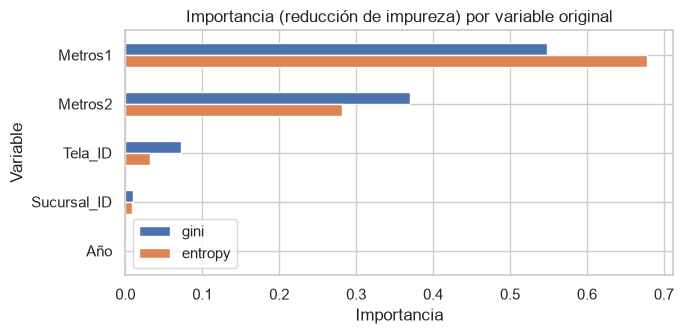

Coeficientes absolutos medios de la logística (variables estandarizadas):


Metros2    2.4283
Metros1    1.6614
Año        0.0965
dtype: float64

In [5]:
# 5.3 Importancia de cada variable original (se suman sus columnas one-hot)
importancias = pd.DataFrame(index=features)
for nombre, arbol in [("gini", arbol_gini), ("entropy", arbol_entropy)]:
    imp = pd.Series(arbol.named_steps["modelo"].feature_importances_, index=nombres)
    importancias[nombre] = [imp[imp.index.str.startswith(var)].sum() for var in features]
importancias = importancias.sort_values("gini", ascending=False)
display(importancias.round(4))

ax = importancias.plot(kind="barh", figsize=(7, 3.5))
ax.set(title="Importancia (reducción de impureza) por variable original", xlabel="Importancia", ylabel="Variable")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

# Comparación con la regresión logística de la actividad 03 (mismas variables y configuración)
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

logit = Pipeline([("escalar", StandardScaler()),
                  ("modelo", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))])
logit.fit(X_train[num_cols], y_train)
coef = pd.DataFrame(logit.named_steps["modelo"].coef_, index=logit.classes_, columns=num_cols)
print("Coeficientes absolutos medios de la logística (variables estandarizadas):")
coef.abs().mean().sort_values(ascending=False).round(4)

,RMSE train,RMSE test,MAE test,R2 test
max_depth,,,,
2,1944.7266,1964.5878,1451.2611,0.2898
4,1675.0657,1675.3439,1248.9193,0.4835
6,1518.4967,1597.2522,1174.1943,0.5305
8,1368.1215,1438.9781,1045.1030,0.6190
12,1080.3565,1193.8388,812.7745,0.7377
None,0.0000,964.4432,418.3971,0.8288


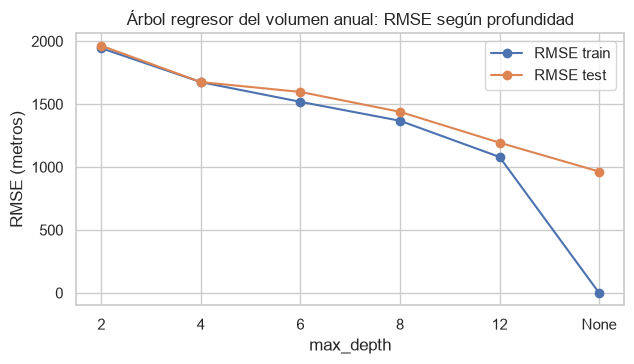

In [6]:
# 5.4 Árbol regresor del volumen anual con distintas profundidades
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

arboles_reg = {}
filas = []
for profundidad in [2, 4, 6, 8, 12, None]:
    arbol_r = crear_pipeline(DecisionTreeRegressor(max_depth=profundidad, random_state=RANDOM_STATE),
                             numericas=["Año"])
    arbol_r.fit(Xr_train, yr_train)
    arboles_reg[profundidad] = arbol_r
    filas.append({"max_depth": str(profundidad),
                  "RMSE train": np.sqrt(mean_squared_error(yr_train, arbol_r.predict(Xr_train))),
                  "RMSE test": np.sqrt(mean_squared_error(yr_test, arbol_r.predict(Xr_test))),
                  "MAE test": mean_absolute_error(yr_test, arbol_r.predict(Xr_test)),
                  "R2 test": r2_score(yr_test, arbol_r.predict(Xr_test))})
tabla_arbol_reg = pd.DataFrame(filas).set_index("max_depth")
display(tabla_arbol_reg.round(4))

ax = tabla_arbol_reg[["RMSE train", "RMSE test"]].plot(marker="o", figsize=(6.5, 3.8))
ax.set(title="Árbol regresor del volumen anual: RMSE según profundidad", xlabel="max_depth", ylabel="RMSE (metros)")
plt.tight_layout()
plt.show()

In [7]:
# 5.5 Tabla acumulada de las actividades 1–5 (métricas en test)
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge

yb_train = y_train.isin(["B", "M"]).astype(int)   # reformulación binaria de la actividad 04
yb_test = y_test.isin(["B", "M"]).astype(int)

logit_bin = Pipeline([("escalar", StandardScaler()),
                      ("modelo", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))])
logit_bin.fit(X_train[num_cols], yb_train)

ridge_completa = Pipeline([
    ("prep", ColumnTransformer([
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), cat_cols),
        ("num", StandardScaler(), ["Año"])])),
    ("modelo", Ridge(alpha=1.0))])
ridge_completa.fit(Xr_train, yr_train)

# Predicciones de test de cada modelo
clasificacion = {
    ("Multiclase", "Baseline"): (y_test, DummyClassifier(strategy="most_frequent").fit(X_train, y_train).predict(X_test)),
    ("Multiclase", "Regresión logística"): (y_test, logit.predict(X_test[num_cols])),
    ("Multiclase", "Árbol gini (depth=4)"): (y_test, pred_gini),
    ("Multiclase", "Árbol entropy (depth=4)"): (y_test, pred_entropy),
    ("Binaria B/M vs S/C", "Baseline"): (yb_test, DummyClassifier(strategy="most_frequent").fit(X_train, yb_train).predict(X_test)),
    ("Binaria B/M vs S/C", "Regresión logística"): (yb_test, logit_bin.predict(X_test[num_cols])),
}
regresion = {
    ("Regresión volumen anual", "Baseline (media)"): DummyRegressor(strategy="mean").fit(Xr_train, yr_train).predict(Xr_test),
    ("Regresión volumen anual", "Lineal (Año)"): LinearRegression().fit(Xr_train[["Año"]], yr_train).predict(Xr_test[["Año"]]),
    ("Regresión volumen anual", "Ridge alpha=1 (Sucursal, Tela, Año)"): ridge_completa.predict(Xr_test),
    ("Regresión volumen anual", "Árbol regresor (depth=4)"): arboles_reg[4].predict(Xr_test),
}

filas = []
for (tarea, modelo), (y_real, pred) in clasificacion.items():
    filas.append({"Tarea": tarea, "Modelo": modelo, "Accuracy": accuracy_score(y_real, pred),
                  "F1 macro": f1_score(y_real, pred, average="macro")})
for (tarea, modelo), pred in regresion.items():
    filas.append({"Tarea": tarea, "Modelo": modelo, "MAE": mean_absolute_error(yr_test, pred),
                  "RMSE": np.sqrt(mean_squared_error(yr_test, pred)), "R2": r2_score(yr_test, pred)})

pd.DataFrame(filas).set_index(["Tarea", "Modelo"]).round(4)

Accuracy  \
Tarea                   Modelo                                          
Multiclase              Baseline                               0.2831   
                        Regresión logística                    0.7336   
                        Árbol gini (depth=4)                   0.6545   
                        Árbol entropy (depth=4)                0.6256   
Binaria B/M vs S/C      Baseline                               0.5449   
                        Regresión logística                    0.8432   
Regresión volumen anual Baseline (media)                          NaN   
                        Lineal (Año)                              NaN   
                        Ridge alpha=1 (Sucursal, Tela, Año)       NaN   
                        Árbol regresor (depth=4)                  NaN   

                                                             F1 macro  \
Tarea                   Modelo                                          
Multiclase              Baseline                               0.1103   
                        Regresión logística                    0.7296   
                        Árbol gini (depth=4)                   0.6460   
                        Árbol entropy (depth=4)                0.6101   
Binaria B/M vs S/C      Baseline                               0.3527   
                        Regresión logística                    0.8431   
Regresión volumen anual Baseline (media)                          NaN   
                        Lineal (Año)                              NaN   
                        Ridge alpha=1 (Sucursal, Tela, Año)       NaN   
                        Árbol regresor (depth=4)                  NaN   

                                                                   MAE  \
Tarea                   Modelo                                           
Multiclase              Baseline                                   NaN   
                        Regresión logística                        NaN   
                        Árbol gini (depth=4)                       NaN   
                        Árbol entropy (depth=4)                    NaN   
Binaria B/M vs S/C      Baseline                                   NaN   
                        Regresión logística                        NaN   
Regresión volumen anual Baseline (media)                     1673.0396   
                        Lineal (Año)                         1660.4733   
                        Ridge alpha=1 (Sucursal, Tela, Año)   836.1548   
                        Árbol regresor (depth=4)             1248.9193   

                                                                  RMSE      R2  
Tarea                   Modelo                                                  
Multiclase              Baseline                                   NaN     NaN  
                        Regresión logística                        NaN     NaN  
                        Árbol gini (depth=4)                       NaN     NaN  
                        Árbol entropy (depth=4)                    NaN     NaN  
Binaria B/M vs S/C      Baseline                                   NaN     NaN  
                        Regresión logística                        NaN     NaN  
Regresión volumen anual Baseline (media)                     2331.7786 -0.0006  
                        Lineal (Año)                         2317.2201  0.0119  
                        Ridge alpha=1 (Sucursal, Tela, Año)  1279.4564  0.6988  
                        Árbol regresor (depth=4)             1675.3439  0.4835

### Explicación del alumno/a

**Decisiones técnicas y justificación:**
- **Clasificación:** comparamos `DecisionTreeClassifier` con `criterion='gini'` y con `'entropy'`, ambos con `max_depth=4`. Usamos todas las features, con los identificadores en one-hot; los árboles no necesitan escalado.
- **Visualización:** el árbol gini hasta profundidad 3. Las importancias de las columnas one-hot se suman por variable original para poder compararlas con los coeficientes de la logística.
- **Árbol regresor de `volumen_anual_metros`:** con `Sucursal_ID`, `Tela_ID` (one-hot) y `Año`, probamos `max_depth` en {2, 4, 6, 8, 12, None} y reportamos train y test para ver cómo cambia el ajuste.
- **Tabla acumulada:** reúne todas las métricas de test de las actividades 1–5. La regresión de referencia es `Ridge(alpha=1)`.

**Interpretación de los resultados:**
- **Árboles con depth = 4:**
  - Gini obtiene un F1 macro de 0,646 en test y entropy 0,610.
  - Los dos quedan **por debajo de la logística** (0,730): con solo 4 niveles, el árbol aproxima con pocos cortes escalonados una frontera que depende de combinaciones de `Metros1` y `Metros2`.
  - El F1 de train (0,64) es casi igual al de test: no hay sobreajuste, hay **falta de capacidad**.
- **Árbol regresor:**
  - Con las features en one-hot, cada corte separa una sola sucursal o tela, así que el árbol necesita mucha profundidad: con depth 4 tiene RMSE 1.675 m (R² 0,48), peor que Ridge (1.279 m).
  - El RMSE de test baja de forma sostenida con la profundidad: 1.194 m en depth 12 y **964 m sin límite** (R² 0,83).
  - Sin límite, el RMSE de train es 0: el árbol aprende el volumen de cada par (sucursal, tela) y lo reutiliza en otros años del mismo par. Mejora a Ridge porque captura la interacción sucursal × tela, pero es la misma memorización de pares que vemos en la clasificación.

**Pregunta de análisis:** ¿Qué variable produce la primera partición? ¿Coinciden las importancias con el modelo lineal?
- **Primera partición:** `Metros1`, en los dos criterios (`Metros1 <= 655,8` en gini y `<= 691,0` en entropy).
  - A la izquierda quedan sobre todo M y B, los de bajo volumen por período.
  - A la derecha quedan C y S.
  - El segundo nivel corta por `Metros2`.
- **Importancias:**
  - Gini: `Metros1` 0,55, `Metros2` 0,37, `Tela_ID` 0,07, `Sucursal_ID` 0,01 y `Año` 0.
  - Coinciden con el modelo lineal en lo esencial: las variables de volumen dominan y `Año` es irrelevante. Cambia el orden: en la logística pesa más `Metros2` (|coef| medio de 2,43 contra 1,66).
  - Las dos medidas no son equivalentes. La importancia del árbol mide reducción de impureza y está sesgada hacia las variables continuas con muchos cortes posibles. El coeficiente mide el efecto lineal sobre el log-odds.

**Limitaciones o mejoras posibles:**
- `max_depth=4` es solo un punto de partida: la Actividad 08 muestra que el árbol mejora con más profundidad.
- Un árbol individual es inestable ante pequeños cambios en los datos, lo que motiva los ensambles.

### Comentarios del docente

[Espacio breve para observaciones sobre esta actividad: aciertos, correcciones o sugerencias.]
